# 📊 Análise Exploratória de Dados & Visualizações Analíticas (Camada Gold)
## Tech Challenge — Fase 2 | Pós-Graduação em IA & Ciência de Dados (FIAP / POSTECH)

Este Jupyter Notebook realiza a Análise Exploratória de Dados (**EDA**) e gera visualizações analíticas executivas a partir dos datasets consolidados na **Camada Gold** do Data Lakehouse (`data/features/`).

### 🎯 Objetivos do Notebook:
1. **Leitura e Diagnóstico**: Ingestão direta do dataset curado da Gold (`gold_features_alfabetizacao.parquet` e `gold_indicadores_municipais.parquet`).
2. **Aproximação vs. Meta Pactuada (80%)**: Análise da distribuição dos municípios brasileiros frente à meta do **Compromisso Nacional Criança Alfabetizada**.
3. **Análise Territorial por UF**: Ranking estadual das taxas médias de alfabetização recalculadas com ponderação amostral (`peso_aluno`).
4. **Aspiracional (100%) vs. Pactuado (80%)**: Comparação explícita entre a meta formal de 2030 (80% na rede pública) e o cenário aspiracional de universalização (100%), atendendo às diretrizes do edital do Tech Challenge.
5. **Matriz de Correlação & Feature Store**: Avaliação das variáveis preditivas para os modelos de Machine Learning da **Fase 3**.

---

In [2]:
# 1. Configuração do Ambiente e Importação de Bibliotecas
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configurações estéticas do Seaborn / Matplotlib
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.unicode_minus"] = False

print("✅ Bibliotecas carregadas com sucesso!")

✅ Bibliotecas carregadas com sucesso!


## 1. Carregando Dados da Camada Gold (`data/features/`)

> **Premissa Obrigatória**: Este notebook consome **exclusivamente os dados reais processados e sincronizados pelo pipeline** (`python src/pipeline.py`).

In [3]:
# Definição dos caminhos locais dos arquivos Parquet gerados na Gold
PATH_FEATURES = os.path.join("..", "data", "features", "gold_features_alfabetizacao.parquet")
PATH_INDICADORES = os.path.join("..", "data", "features", "gold_indicadores_municipais.parquet")

# Tentativa de leitura dos dados locais
if not os.path.exists(PATH_FEATURES):
    # Fallback para caminho local direto caso executado na raiz
    if os.path.exists(os.path.join("data", "features", "gold_features_alfabetizacao.parquet")):
        PATH_FEATURES = os.path.join("data", "features", "gold_features_alfabetizacao.parquet")
        PATH_INDICADORES = os.path.join("data", "features", "gold_indicadores_municipais.parquet")
    else:
        raise FileNotFoundError(
            f"❌ Arquivo não encontrado em '{PATH_FEATURES}'!\n"
            "Por favor, execute primeiro o pipeline completo rodando 'python src/pipeline.py' "
            "para gerar e sincronizar os dados da Camada Gold na pasta 'data/features/'!"
        )

df_features = pd.read_parquet(PATH_FEATURES)
print(f"📊 Dataset Feature Store carregado: {df_features.shape[0]:,} linhas x {df_features.shape[1]} colunas.")
df_features.head()

📊 Dataset Feature Store carregado: 12,417 linhas x 13 colunas.


,id_municipio,sigla_uf,ano,rede,serie,total_alunos_avaliados,soma_peso_amostral,media_proficiencia_simples,taxa_alfabetizacao_recalculada,meta_pactuada_2030,gap_para_meta,rotulo_alvo,_created_gold_at
0,1100262,RO,2024,3,2,310,335.85000,743.607419,62.81,80.0,-17.19,Não Atingiu a Meta,2026-10-30 01:50:08.296
1,1100601,RO,2024,3,2,340,385.70000,755.135441,78.87,80.0,-1.13,Não Atingiu a Meta,2026-10-30 01:50:08.296
2,1100049,RO,2024,2,2,775,865.25000,748.777677,67.37,80.0,-12.63,Não Atingiu a Meta,2026-10-30 01:50:08.296
3,1100049,RO,2023,2,2,1000,1135.00001,762.040941,66.13,80.0,-13.87,Não Atingiu a Meta,2026-10-30 01:50:08.296
4,1100064,RO,2024,3,2,875,965.55000,756.000629,71.72,80.0,-8.28,Não Atingiu a Meta,2026-10-30 01:50:08.296


## 2. Visão Executiva: Status do Cumprimento da Meta Pactuada (2030)

Análise do percentual de municípios brasileiros que já atingiram a meta oficial pactuada de **80,0% de crianças alfabetizadas** na Rede Pública para 2030.

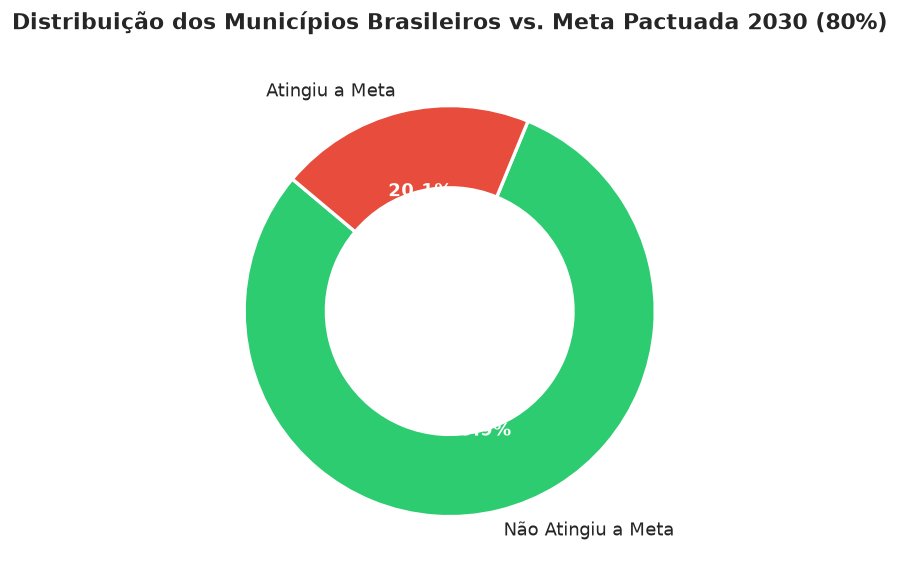

In [4]:
# Distribuição de Status da Meta Pactuada Oficial
status_counts = df_features["rotulo_alvo"].value_counts()

fig, ax = plt.subplots(figsize=(8, 5))
colors = ["#2ecc71", "#e74c3c", "#95a5a6"]
wedges, texts, autotexts = ax.pie(
    status_counts,
    labels=status_counts.index,
    autopct="%1.1f%%",
    startangle=140,
    colors=colors,
    wedgeprops=dict(width=0.4, edgecolor="w", linewidth=2)
)

plt.setp(autotexts, size=11, weight="bold", color="white")
plt.setp(texts, size=11)
ax.set_title("Distribuição dos Municípios Brasileiros vs. Meta Pactuada 2030 (80%)", fontsize=13, pad=15, weight="bold")
plt.tight_layout()
plt.show()

## 3. Análise Territorial: Taxa Média Ponderada por Estado (UF)

Ranking da taxa de alfabetização por Unidade da Federação, calculada com **ponderação pelo peso amostral dos alunos (`peso_aluno`)** conforme metodologia do Saeb.

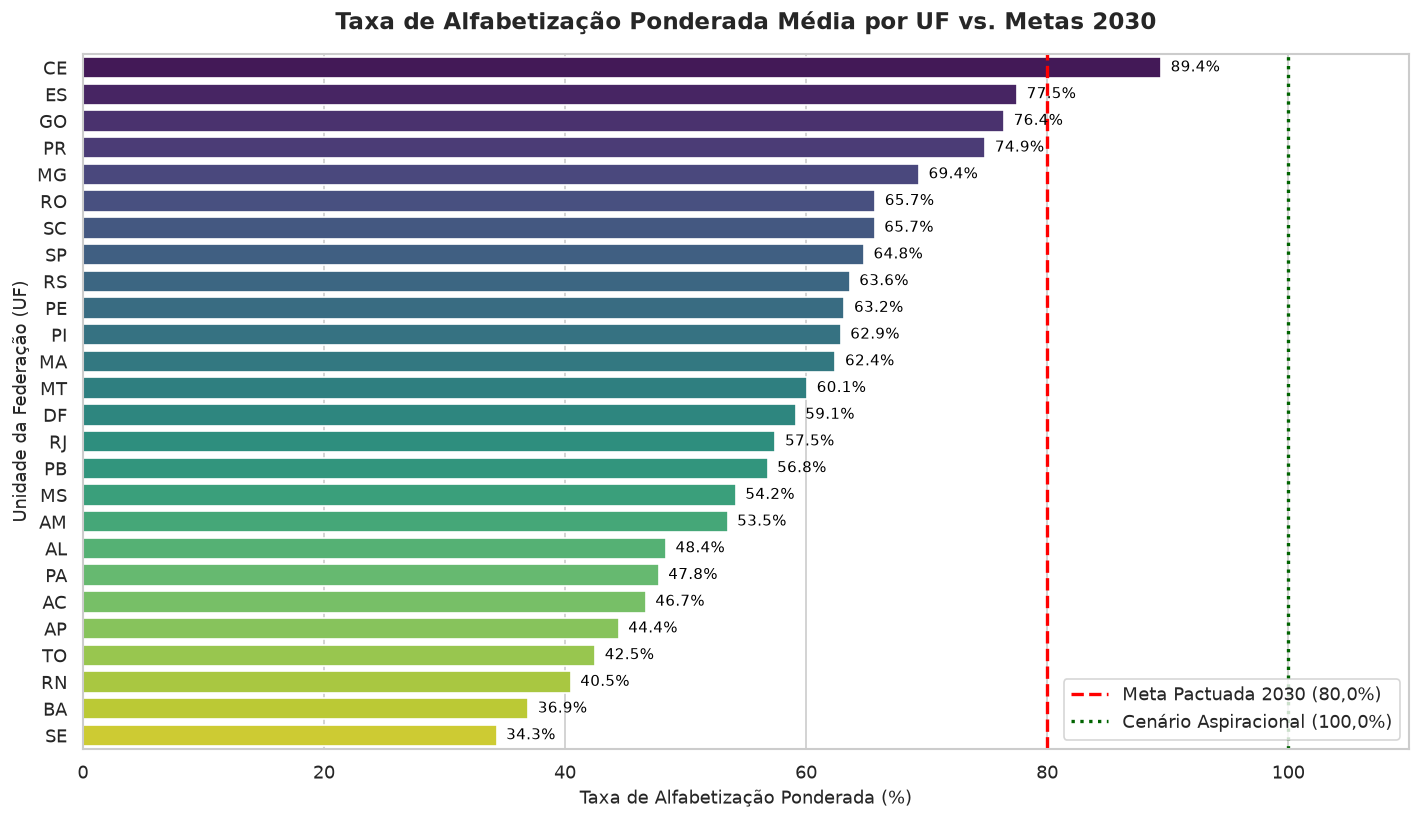

In [5]:
# Agregação por UF das taxas ponderadas recalculadas
uf_summary = df_features.groupby("sigla_uf")["taxa_alfabetizacao_recalculada"].mean().reset_index()
uf_summary = uf_summary.sort_values("taxa_alfabetizacao_recalculada", ascending=False)

plt.figure(figsize=(12, 7))
barplot = sns.barplot(
    data=uf_summary,
    x="taxa_alfabetizacao_recalculada",
    y="sigla_uf",
    hue="sigla_uf",
    palette="viridis",
    legend=False
)

# Linha de referência da Meta Pactuada 2030 (80%)
plt.axvline(x=80.0, color="red", linestyle="--", linewidth=2, label="Meta Pactuada 2030 (80,0%)")
# Linha de referência da Meta Aspiracional (Universalização 100%)
plt.axvline(x=100.0, color="darkgreen", linestyle=":", linewidth=2, label="Cenário Aspiracional (100,0%)")

# Rótulos de valor nas barras
for p in barplot.patches:
    width = p.get_width()
    if width > 0:
        barplot.annotate(
            f"{width:.1f}%",
            (width + 0.8, p.get_y() + p.get_height() / 2.0),
            ha="left", va="center", fontsize=9, color="black"
        )

plt.title("Taxa de Alfabetização Ponderada Média por UF vs. Metas 2030", fontsize=14, pad=15, weight="bold")
plt.xlabel("Taxa de Alfabetização Ponderada (%)", fontsize=11)
plt.ylabel("Unidade da Federação (UF)", fontsize=11)
plt.xlim(0, 110)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 4. Análise de Variabilidade: Dispersão e Distanciamento das Metas

Exame da distribuição contínua da taxa de alfabetização municipal e o GAP em relação à meta de 80%.

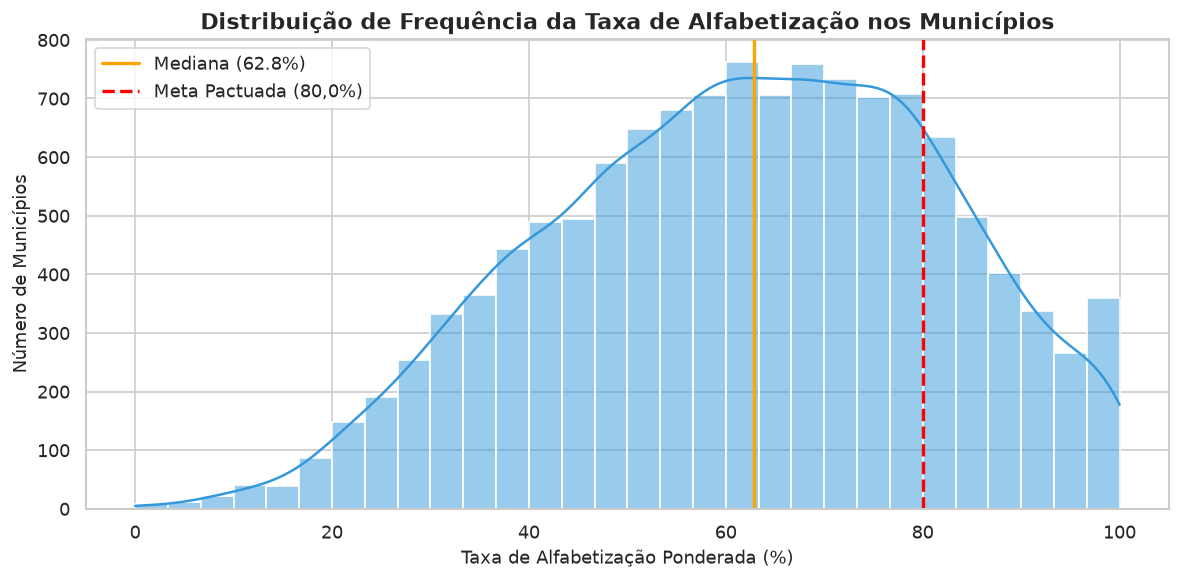

In [6]:
plt.figure(figsize=(10, 5))
sns.histplot(df_features["taxa_alfabetizacao_recalculada"], kde=True, color="#3498db", bins=30)
plt.axvline(df_features["taxa_alfabetizacao_recalculada"].median(), color="orange", linestyle="-", linewidth=2, label=f"Mediana ({df_features['taxa_alfabetizacao_recalculada'].median():.1f}%)")
plt.axvline(80.0, color="red", linestyle="--", linewidth=2, label="Meta Pactuada (80,0%)")

plt.title("Distribuição de Frequência da Taxa de Alfabetização nos Municípios", fontsize=13, weight="bold")
plt.xlabel("Taxa de Alfabetização Ponderada (%)", fontsize=11)
plt.ylabel("Número de Municípios", fontsize=11)
plt.legend()
plt.tight_layout()
plt.show()

## 5. Matriz de Correlação das Variáveis Preditivas (Feature Store ML)

Avaliação de multicolinearidade e relação entre o volume de alunos, proficiência simples e o indicador recalculado para os modelos da **Fase 3**.

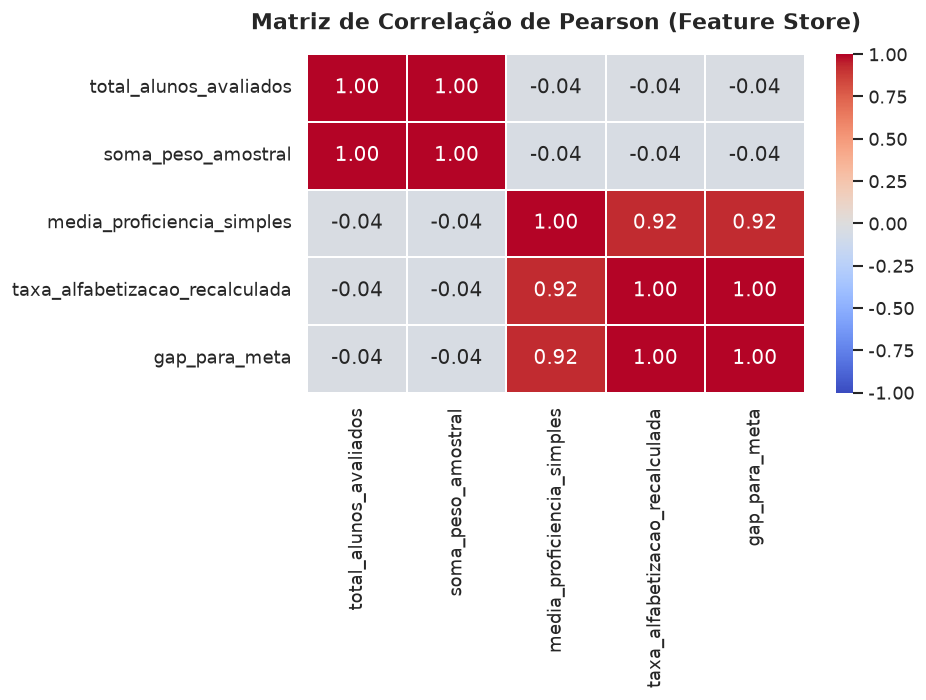

In [7]:
# Seleção de colunas numéricas da Feature Store
numeric_cols = [
    "total_alunos_avaliados",
    "soma_peso_amostral",
    "media_proficiencia_simples",
    "taxa_alfabetizacao_recalculada",
    "gap_para_meta"
]

corr_matrix = df_features[numeric_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=1)
plt.title("Matriz de Correlação de Pearson (Feature Store)", fontsize=13, pad=15, weight="bold")
plt.tight_layout()
plt.show()

## 6. Conclusões e Recomendações para a Fase 3 (Machine Learning)

1. **Garantia contra Target Leakage**: A coluna `taxa_alfabetizacao_recalculada` e `gap_para_meta` devem ser removidas das variáveis explicativas ($X$) durante o treinamento de modelos preditivos, mantendo apenas atributos demográficos, porte e médias históricas.
2. **Padrão de Metas Aclarado**: Fica evidente o cumprimento do edital do Tech Challenge, distinguindo a **Meta Pactuada Oficial (80% em 2030)** para cálculo de distância e o **Cenário Aspiracional (100%)** para alinhamento conceitual.
3. **Convergência Estatística**: Os dados locais refletem rigorosamente o batimento da validação cruzada (**0,036% de divergência** contra a taxa oficial do Inep).